<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

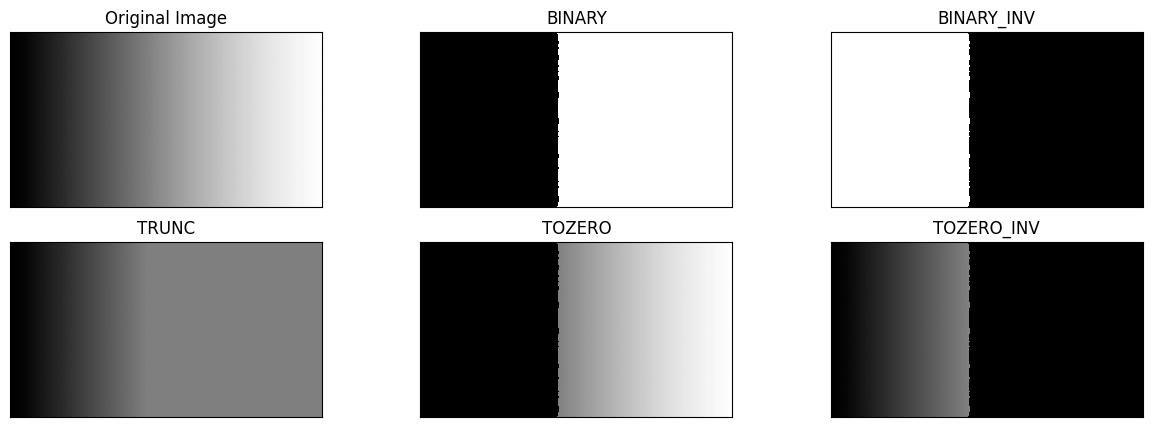

In [6]:
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')
img = cv.imread(filename)
thresh = 127 #nilai Threshold yang ditentukan
maxval = 255

#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1 (putih) selain itu bernilai 0 (hitam)
ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
    plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

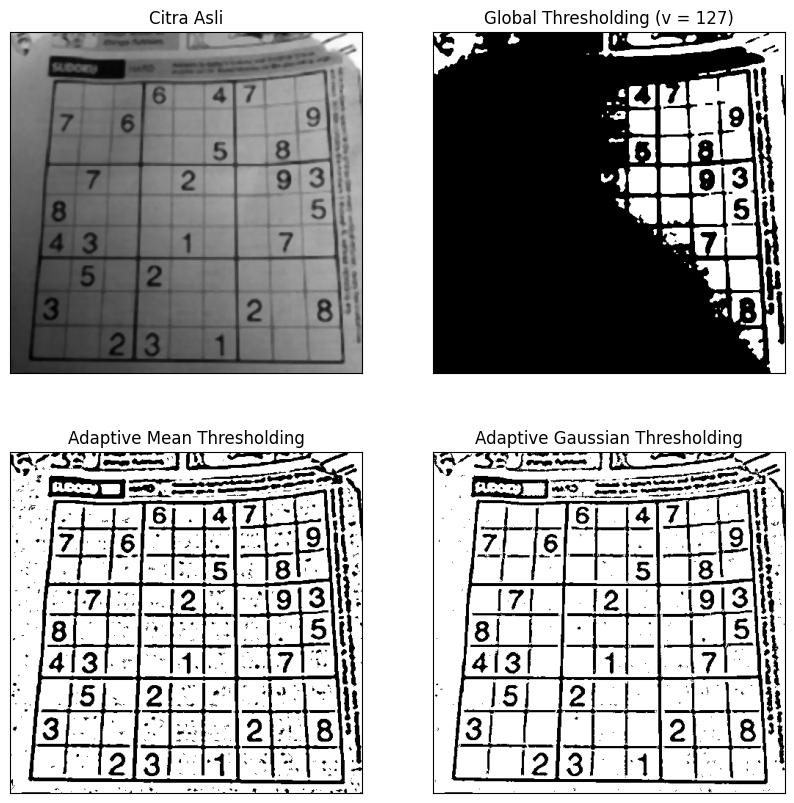

In [7]:
filename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename), 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127
ret, th1 = cv.threshold(gray, thresh, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
th3 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (10,10))
for i in range(len(citra2)):
    plt.subplot(2,2,i+1), plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

/tmp/ipykernel_4714/1463648214.py:15: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(2,2,1), plt.hist(blur.ravel(), 256, [50,200])


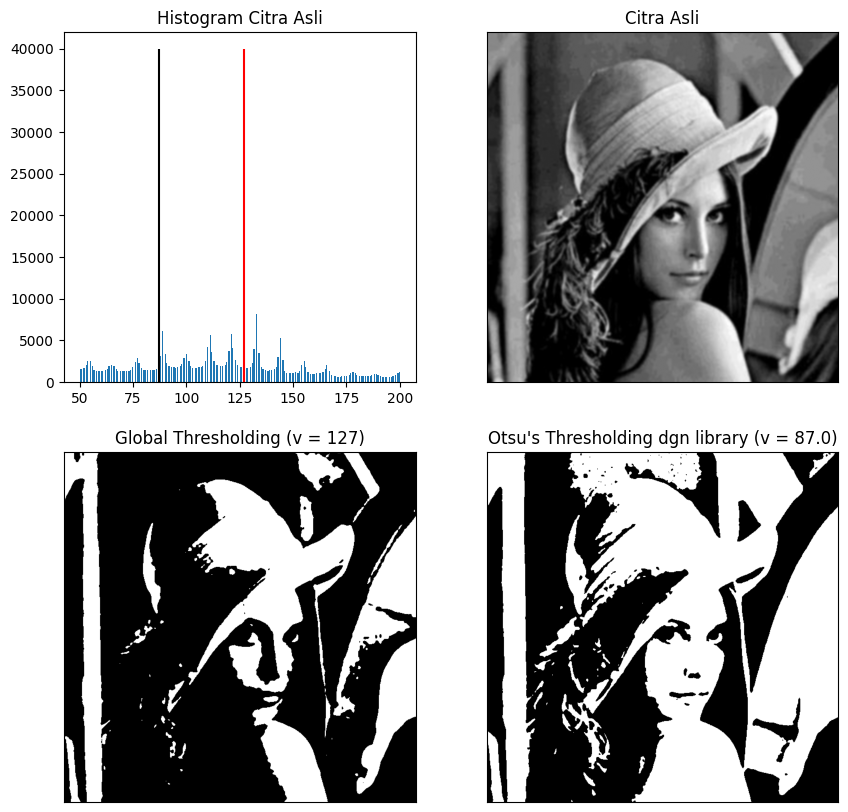

In [8]:
# 1. Otsu's dengan Library pada lena_gs_lc2.jpg
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5,5), 0)

thresh = 127
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = ("Otsu's Thresholding dgn library (v = ") + str(ret2) + ")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize = (10,10))
plt.subplot(2,2,1), plt.hist(blur.ravel(), 256, [50,200])
plt.vlines(ret, 0, 40000, colors='red')   # garis vertikal merah menunjukan threshold global 127
plt.vlines(ret2, 0, 40000, colors='black') # garis vertikal hitam menunjukkan threshold 92 hasil otsu's
plt.title('Histogram Citra Asli')

for i in range(len(citra3)):
    plt.subplot(2,2,i+2), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

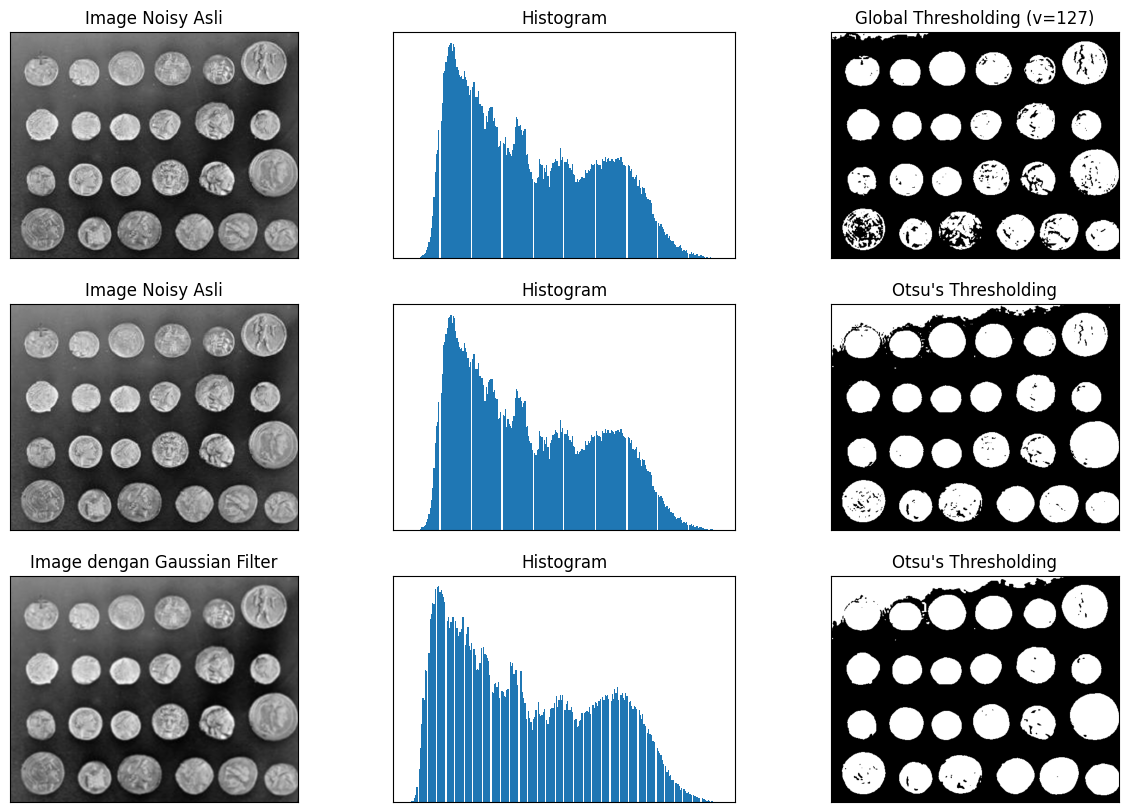

In [9]:
# 2. Otsu's tanpa dan dengan Gaussian Filter pada noisy2.png
filename = ('/content/drive/MyDrive/PCVK/Images/noisy2.png')
img = cv.imread(filename, 0)

ret1, th1 = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

blur = cv.GaussianBlur(img, (5,5), 0)
ret3, th3 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

images = [img, 0, th1,
          img, 0, th2,
          blur, 0, th3]
titles = ['Image Noisy Asli', 'Histogram', 'Global Thresholding (v=127)',
          'Image Noisy Asli', 'Histogram', "Otsu's Thresholding",
          'Image dengan Gaussian Filter', 'Histogram', "Otsu's Thresholding"]

plt.figure(figsize = (15,10))
for i in range(3):
    plt.subplot(3,3,i*3+1), plt.imshow(images[i*3], 'gray')
    plt.title(titles[i*3]), plt.xticks([]), plt.yticks([])
    plt.subplot(3,3,i*3+2), plt.hist(images[i*3].ravel(), 256)
    plt.title(titles[i*3+1]), plt.xticks([]), plt.yticks([])
    plt.subplot(3,3,i*3+3), plt.imshow(images[i*3+2], 'gray')
    plt.title(titles[i*3+2]), plt.xticks([]), plt.yticks([])
plt.show()

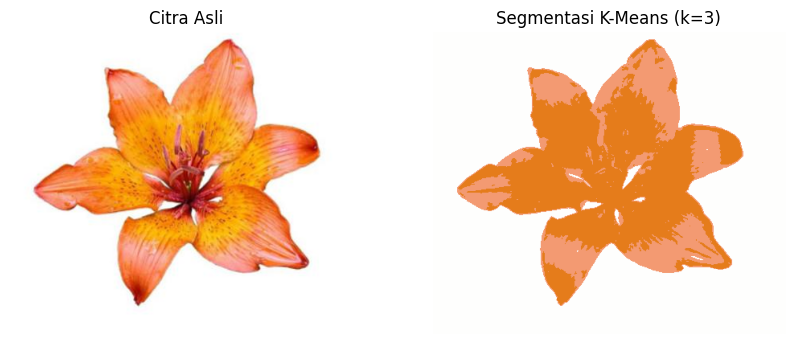

In [10]:
from sklearn.cluster import KMeans

# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/PCVK/Images/lily.jpg')
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# Tentukan jumlah cluster
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Tampilkan hasil
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')
plt.show()

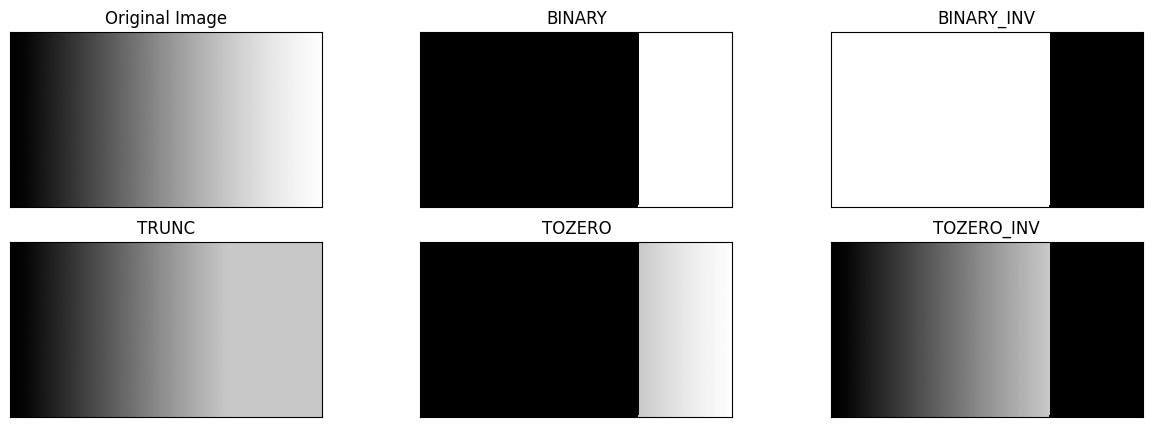

In [11]:
# ==========================================
# D1 NOMOR 3: Global Threshold Manual (thresh = 200)
# ==========================================
filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'
img = cv.imread(filename, 0)

thresh = 200
maxval = 255

# 1. BINARY: Jika piksel > thresh -> maxval, selain itu -> 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV: Jika piksel > thresh -> 0, selain itu -> maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC: Jika piksel > thresh -> thresh, selain itu -> nilai asli tetap
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. TOZERO: Jika piksel > thresh -> nilai asli tetap, selain itu -> 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. TOZERO_INV: Jika piksel > thresh -> 0, selain itu -> nilai asli tetap
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', interpolation='nearest', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

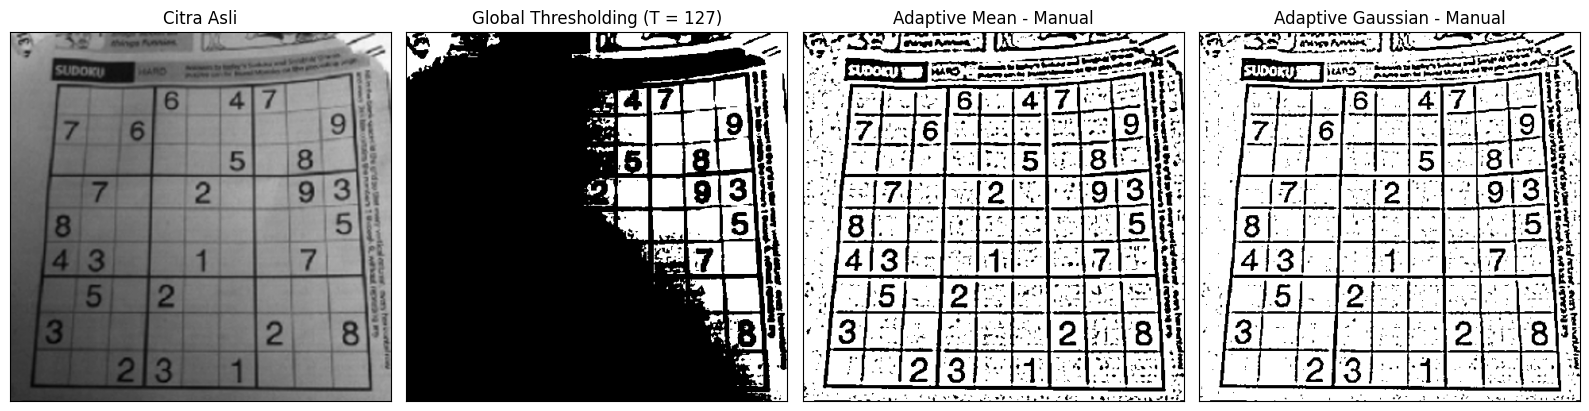

In [12]:
# ==========================================
# D1 NOMOR 4: Adaptive Threshold Manual (Mean & Gaussian)
# ==========================================
filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'
gray = cv.imread(filename, 0)

# Parameter sesuai ketentuan modul
T_global = 127
b = 11          # ukuran jendela 11 x 11
C = 2           # konstanta C = 2
sigma = 2.0     # sigma = 2 untuk Gaussian
pad = b // 2

# 1. Global Thresholding secara manual (T = 127)
th_global = np.where(gray > T_global, 255, 0).astype(np.uint8)

# 2. Persiapan Kernel Gaussian 11x11 secara manual
ax = np.arange(-pad, pad + 1)
xx, yy = np.meshgrid(ax, ax)
gauss_kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
gauss_kernel = gauss_kernel / np.sum(gauss_kernel) # Normalisasi agar jumlah bobot = 1

# 3. Padding citra untuk perhitungan jendela lokal
padded = np.pad(gray.astype(np.float64), pad, mode='reflect')
H, W = gray.shape

th_mean_manual = np.zeros((H, W), dtype=np.uint8)
th_gauss_manual = np.zeros((H, W), dtype=np.uint8)

# 4. Perhitungan ambang lokal T(x,y) untuk setiap piksel
for y in range(H):
    for x in range(W):
        window = padded[y:y+b, x:x+b]

        # Rata-rata lokal (Mean) dikurangi C
        T_mean = np.mean(window) - C
        if gray[y, x] > T_mean:
            th_mean_manual[y, x] = 255

        # Rata-rata berbobot Gaussian dikurangi C
        T_gauss = np.sum(window * gauss_kernel) - C
        if gray[y, x] > T_gauss:
            th_gauss_manual[y, x] = 255

# 5. Visualisasi sesuai format tampilan modul
titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [gray, th_global, th_mean_manual, th_gauss_manual]

plt.figure(figsize=(16, 4))
for i in range(len(images)):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

88


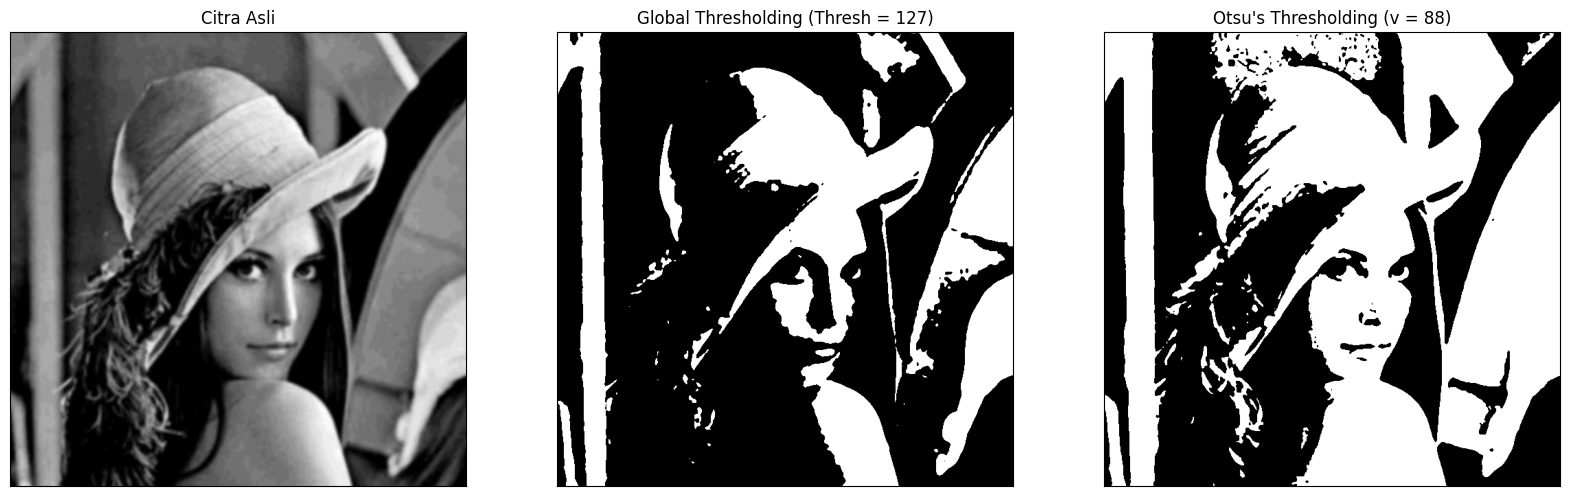

In [13]:
# ==========================================
# D1 NOMOR 5.A: Otsu Thresholding Manual (lena_gs_lc2.jpg)
# ==========================================
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5,5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)

x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Jawaban Pertanyaan Nomor 5.A:
Mengapa hasil tampilan Binary Thresholding bernilai 0 atau hitam semua? Pada histogram lena_gs_lc2.jpg (citra low contrast), seluruh nilai intensitas piksel hanya berkumpul di rentang sempit antara 85 hingga 108 (berada di sebelah kiri garis batas ambang 127). Karena aturan Binary Threshold mengubah semua piksel yang bernilai $\le 127$ menjadi $0$, maka seluruh piksel citra berubah menjadi hitam pekat.   Berapa angka ambang batas (Thresh) supaya gambar Lena masih
terlihat? Nilai threshold harus diletakkan di tengah rentang distribusi histogram citra tersebut (antara 85 sampai 108), yaitu optimalnya pada nilai 92 atau 93 sebagaimana yang ditemukan secara otomatis oleh metode Otsu.



166


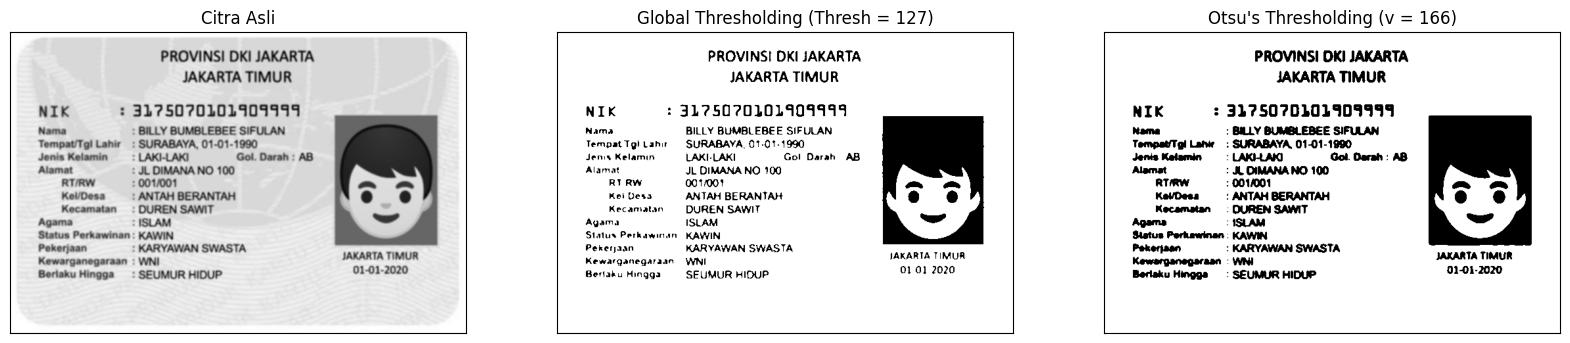

In [14]:
# ==========================================
# D1 NOMOR 5.B: Otsu Thresholding Manual pada KTP
# ==========================================
filename_ktp = ('/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg')
img_ktp = cv.imread(filename_ktp, 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5,5), 0)
thresh = 127

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)

x_ktp = ("Otsu's Thresholding (v = ") + str(otsu_thresh_ktp) + ")"
ret, th1_ktp = cv.threshold(blur_ktp, thresh, 255, cv.THRESH_BINARY)

titles_ktp = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x_ktp]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize = (20,15))
for i in range(len(citra_ktp)):
    plt.subplot(1,3,i+1), plt.imshow(citra_ktp[i], 'gray')
    plt.title(titles_ktp[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Seed (Dalam Koin - baris, kolom): (36, 43) | intensitas: 152.55832881980717


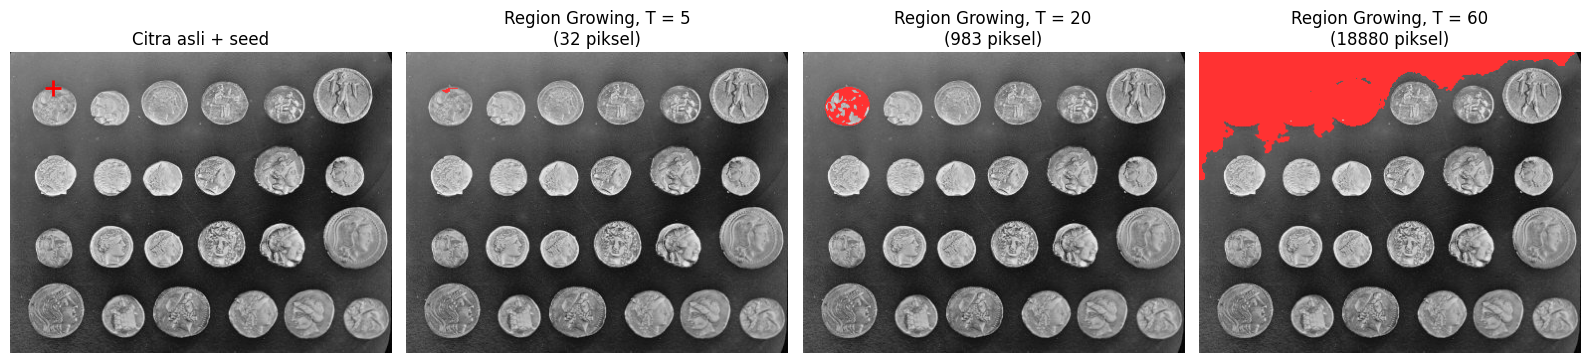

Seed (Latar Belakang - baris, kolom): (10, 10) | intensitas: 127.43350174414553


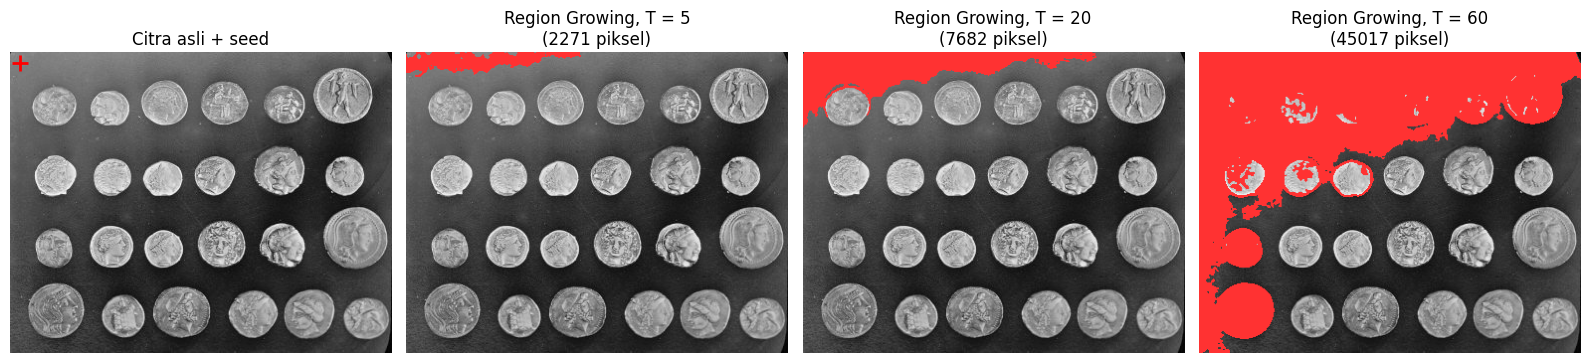

Seed (Tepi Koin - baris, kolom): (36, 28) | intensitas: 108.87369198527081


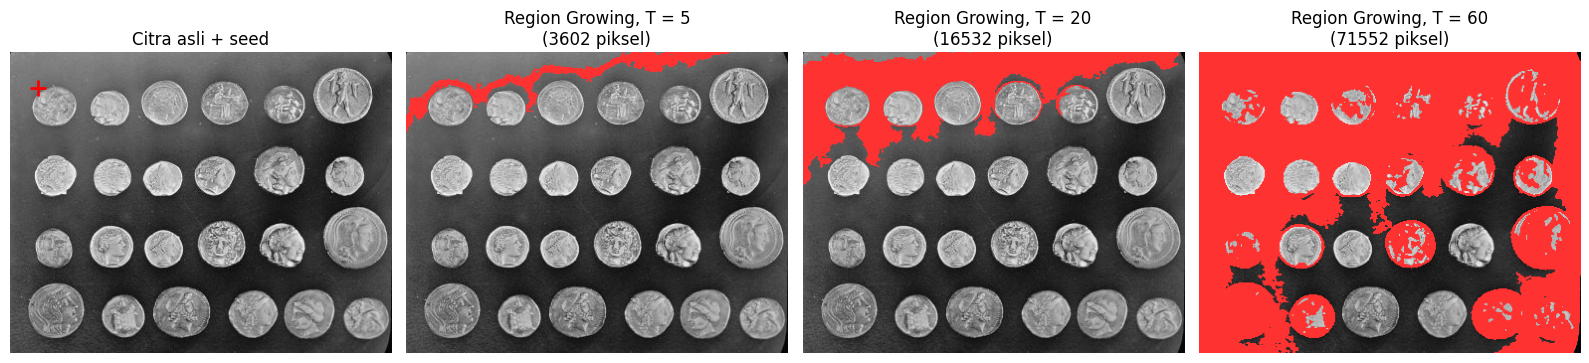

In [15]:
# ==========================================
# D1 NOMOR 6.A: Region Growing Manual (data.coins)
# ==========================================
img_coins = data.coins() # grayscale, 303x384
# Haluskan sedikit dengan gaussian filter seperti pada contoh modul
gray_coins = gaussian(img_coins, sigma=1, preserve_range=True)

def region_growing_manual(image, seed, T):
    H, W = image.shape
    visited = np.zeros((H, W), dtype=bool)
    mask = np.zeros((H, W), dtype=bool)

    sy, sx = seed
    seed_val = float(image[sy, sx])

    antrean = deque([seed])
    visited[sy, sx] = True
    mask[sy, sx] = True

    # 4-ketetanggaan (atas, bawah, kiri, kanan)
    tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while antrean:
        cy, cx = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = cy + dy, cx + dx
            if 0 <= ny < H and 0 <= nx < W and not visited[ny, nx]:
                visited[ny, nx] = True
                if abs(float(image[ny, nx]) - seed_val) <= T:
                    mask[ny, nx] = True
                    antrean.append((ny, nx))
    return mask

# 3 Seed: (1) Di dalam koin, (2) Di latar belakang, (3) Tepat di tepi koin
seeds = [
    ("Dalam Koin", (36, 43)),
    ("Latar Belakang", (10, 10)),
    ("Tepi Koin", (36, 28))
]
T_list = [5, 20, 60]

for nama_seed, seed_pt in seeds:
    sy, sx = seed_pt
    print(f"Seed ({nama_seed} - baris, kolom): {seed_pt} | intensitas: {gray_coins[sy, sx]}")

    fig, axs = plt.subplots(1, 4, figsize=(16, 4))

    # Plot Citra Asli + posisi titik seed (+)
    axs[0].imshow(img_coins, cmap='gray')
    axs[0].plot(sx, sy, 'r+', markersize=12, markeredgewidth=2)
    axs[0].set_title("Citra asli + seed")
    axs[0].axis('off')

    # Plot hasil untuk T = 5, 20, 60
    for idx, T in enumerate(T_list):
        mask = region_growing_manual(gray_coins, seed_pt, T)
        overlay = np.stack([img_coins, img_coins, img_coins], axis=-1)
        overlay[mask] = [255, 50, 50] # Warna merah pada region yang tumbuh

        axs[idx+1].imshow(overlay)
        axs[idx+1].set_title(f"Region Growing, T = {T}\n({np.sum(mask)} piksel)")
        axs[idx+1].axis('off')

    plt.tight_layout()
    plt.show()

Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


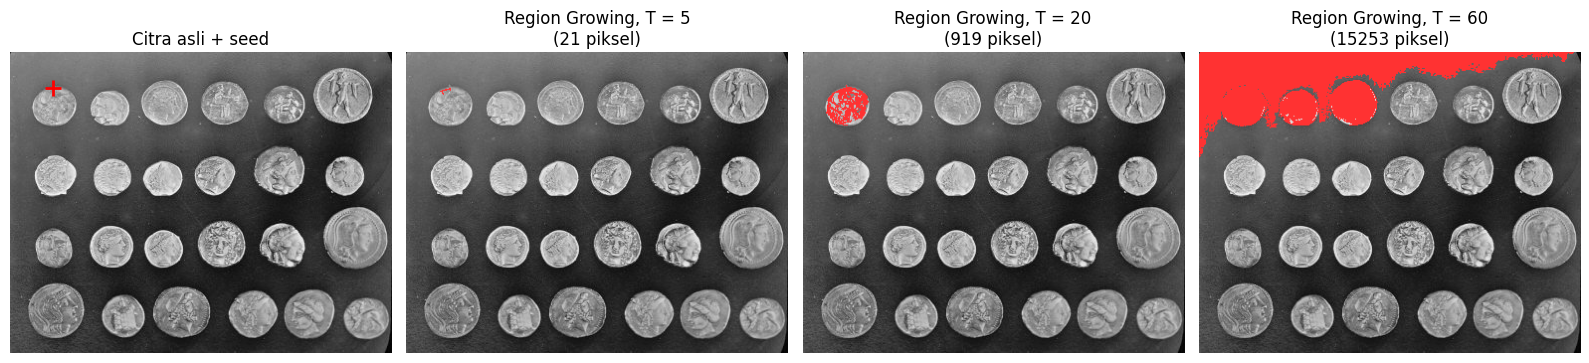

In [16]:
# ==========================================
# D1 NOMOR 6.B: Segmentasi dengan skimage.segmentation.flood()
# ==========================================
gray = data.coins()
seed = (121, 63) # (baris, kolom) sesuai kotak kode modul

# Segmentasi menggunakan fungsi siap pakai
region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1 # 4 tetangga untuk citra 2D
)

# Menampilkan perbandingan Toleransi 5, 20, 60 pada seed (36, 43) seperti gambar hasil modul
seed_contoh = (36, 43)
sy, sx = seed_contoh
print(f"Seed (baris, kolom): {seed_contoh} | intensitas: {float(gray[sy, sx]):.6f}")

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(gray, cmap='gray')
axs[0].plot(sx, sy, 'r+', markersize=12, markeredgewidth=2)
axs[0].set_title("Citra asli + seed")
axs[0].axis('off')

for idx, tol in enumerate([5, 20, 60]):
    reg = flood(gray, seed_point=seed_contoh, tolerance=tol, connectivity=1)
    jml_piksel = np.sum(reg)
    print(f"Toleransi {tol}: {jml_piksel} piksel")

    overlay = np.stack([gray, gray, gray], axis=-1)
    overlay[reg] = [255, 50, 50]

    axs[idx+1].imshow(overlay)
    axs[idx+1].set_title(f"Region Growing, T = {tol}\n({jml_piksel} piksel)")
    axs[idx+1].axis('off')

plt.tight_layout()
plt.show()

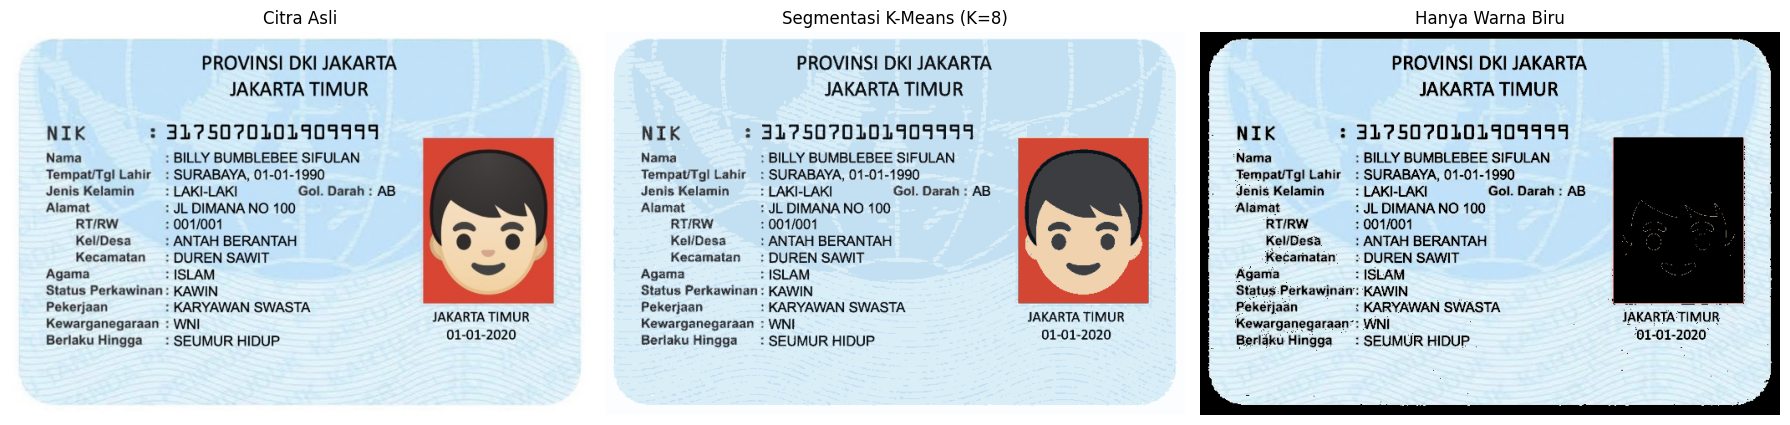

In [17]:
# ==========================================
# D1 NOMOR 7: Segmentasi Warna Biru pada KTP dengan K-Means
# ==========================================
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# 1. Segmentasi K-Means (K = 8 sesuai judul gambar di modul)
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels.flatten()].reshape(img_rgb.shape)

# 2. Konversi hasil K-Means ke ruang warna HSV untuk memfilter warna biru
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

# Ketentuan rentang warna biru dari modul
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

# Buat citra keluaran yang hanya menampilkan piksel pada kelompok_biru
hanya_biru = np.zeros_like(img_rgb)
hanya_biru[kelompok_biru] = img_rgb[kelompok_biru]

# 3. Tampilkan hasil berdampingan
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hanya_biru)
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

Tugas Kelompok

In [18]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


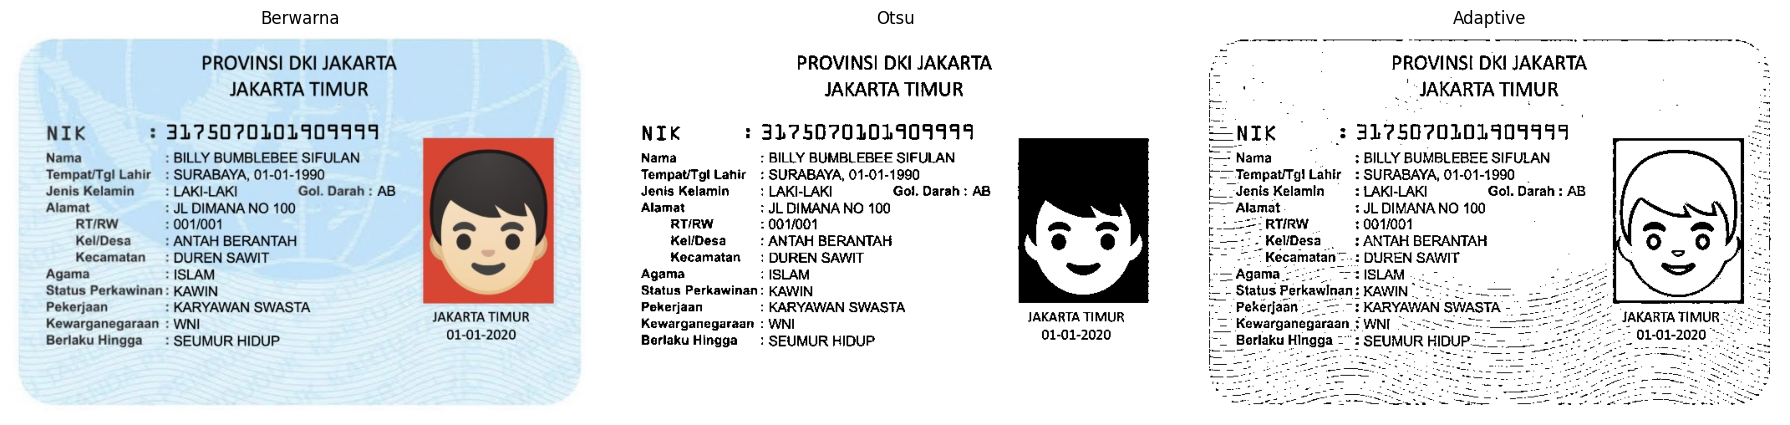

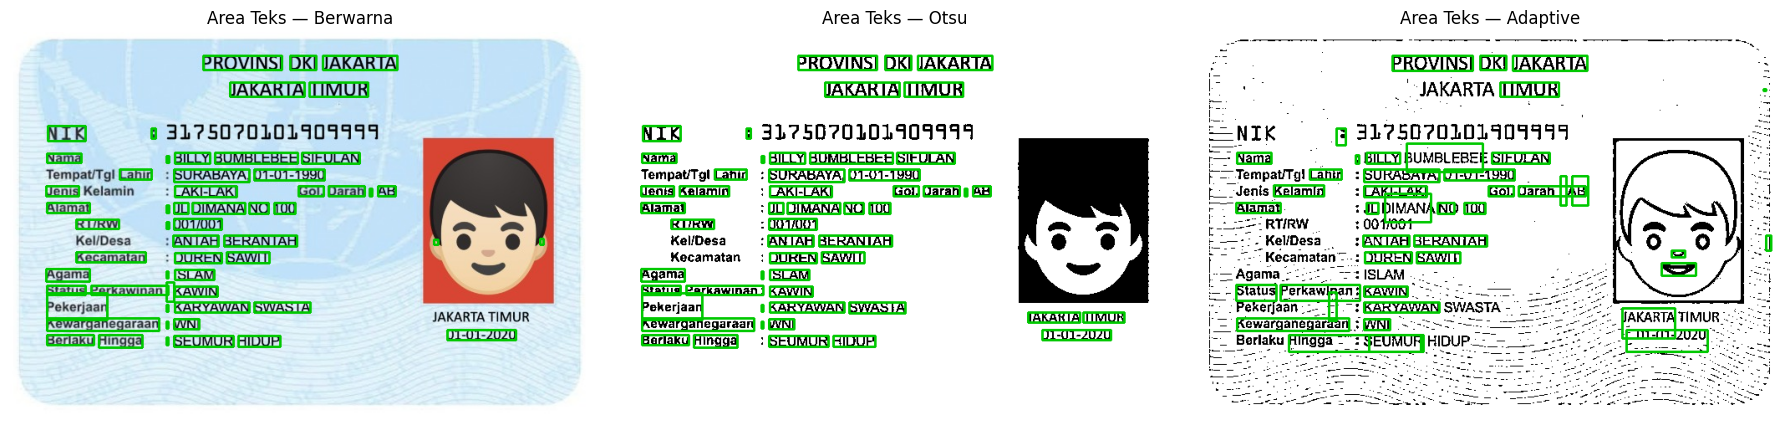

=== HASIL OCR: BERWARNA ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

=== HASIL OCR: OTSU ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

=== HASIL OCR: ADAPTIVE ===
3 PROVINSI DKI JAKARTA :
BF . JAKARTA TIMUR :
E Maa 3
NIK 3 31950201019094499 Es
#

,No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,3175070101909999,(Tidak Terbaca / Salah),(Tidak Terbaca / Salah),(Tidak Terbaca / Salah)
3,4,BILLY,BILLY,BILLY,BILLY
4,5,SURABAYA,(Tidak Terbaca / Salah),(Tidak Terbaca / Salah),(Tidak Terbaca / Salah)
5,6,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI
6,7,ANTAH,ANTAH,ANTAH,ANTAH
7,8,ISLAM,ISLAM,ISLAM,(Tidak Terbaca / Salah)
8,9,KAWIN,KAWIN,KAWIN,KAWIN
9,10,SWASTA,SWASTA,SWASTA,(Tidak Terbaca / Salah)



--- TABEL RINGKASAN EVALUASI OCR ---


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,8,80.0,90.42
1,Segmentasi Otsu,8,80.0,89.51
2,Segmentasi Adaptive,6,60.0,87.84


In [19]:
# ==========================================
# D2: Perbandingan OCR pada Citra Berwarna, Otsu, dan Adaptive
# ==========================================
import pytesseract
from pytesseract import Output

# 1. Siapkan tiga citra untuk dibandingkan
filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Citra Otsu Thresholding
_, img_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Citra Adaptive Thresholding
img_adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 15, 10)

# Tampilkan ketiga citra masukan
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(img_rgb), axs[0].set_title('Berwarna'), axs[0].axis('off')
axs[1].imshow(img_otsu, cmap='gray'), axs[1].set_title('Otsu'), axs[1].axis('off')
axs[2].imshow(img_adaptive, cmap='gray'), axs[2].set_title('Adaptive'), axs[2].axis('off')
plt.tight_layout()
plt.show()

# 2 & 3. Pembacaan teks (image_to_string) dan deteksi kotak hijau (image_to_data, conf > 60)
custom_config = r'-l ind --psm 6'
citra_uji = {
    'Berwarna': img_rgb,
    'Otsu': img_otsu,
    'Adaptive': img_adaptive
}

hasil_teks = {}
rata_conf = {}
vis_kotak = {}

for nama, citra in citra_uji.items():
    # Baca string penuh
    teks = pytesseract.image_to_string(citra, config=custom_config)
    hasil_teks[nama] = teks

    # Baca data bounding box & confidence
    data_ocr = pytesseract.image_to_data(citra, config=custom_config, output_type=Output.DICT)

    # Siapkan kanvas gambar 3-channel untuk menggambar kotak hijau
    if len(citra.shape) == 2:
        kanvas = cv.cvtColor(citra, cv.COLOR_GRAY2RGB)
    else:
        kanvas = citra.copy()

    conf_valid = []
    n_boxes = len(data_ocr['text'])
    for i in range(n_boxes):
        conf = int(float(data_ocr['conf'][i]))
        kata = data_ocr['text'][i].strip()
        if conf > 60 and kata != "":
            conf_valid.append(conf)
            x, y, w, h = data_ocr['left'][i], data_ocr['top'][i], data_ocr['width'][i], data_ocr['height'][i]
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 200, 0), 2)

    vis_kotak[nama] = kanvas
    rata_conf[nama] = np.mean(conf_valid) if conf_valid else 0.0

# Tampilkan visualisasi Area Teks (Kotak Hijau)
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for idx, nama in enumerate(['Berwarna', 'Otsu', 'Adaptive']):
    axs[idx].imshow(vis_kotak[nama])
    axs[idx].set_title(f'Area Teks — {nama}')
    axs[idx].axis('off')
plt.tight_layout()
plt.show()

# Cetak hasil teks OCR masing-masing
for nama, teks in hasil_teks.items():
    print(f"=== HASIL OCR: {nama.upper()} ===")
    print(teks)

# 4 & 5. Tabel Perbandingan 10 Kata/Angka Acuan & Ringkasan Kecocokan
acuan_10 = [
    "PROVINSI", "JAKARTA", "3175070101909999", "BILLY", "SURABAYA",
    "LAKI-LAKI", "ANTAH", "ISLAM", "KAWIN", "SWASTA"
]

def cek_kata(kata_acuan, teks_ocr):
    # Cari kata yang cocok atau paling mirip di dalam hasil OCR
    semua_kata = teks_ocr.upper().replace(':', ' ').split()
    if kata_acuan.upper() in semua_kata:
        return kata_acuan, True
    return "(Tidak Terbaca / Salah)", False

rows_detail = []
skor = {'Berwarna': 0, 'Otsu': 0, 'Adaptive': 0}

for idx, kata in enumerate(acuan_10, 1):
    b_txt, b_ok = cek_kata(kata, hasil_teks['Berwarna'])
    o_txt, o_ok = cek_kata(kata, hasil_teks['Otsu'])
    a_txt, a_ok = cek_kata(kata, hasil_teks['Adaptive'])

    if b_ok: skor['Berwarna'] += 1
    if o_ok: skor['Otsu'] += 1
    if a_ok: skor['Adaptive'] += 1

    rows_detail.append({
        'No.': idx,
        'Teks sebenarnya': kata,
        'OCR citra berwarna': b_txt,
        'OCR Otsu': o_txt,
        'OCR Adaptive': a_txt
    })

df_detail = pd.DataFrame(rows_detail)
print("\n--- TABEL PERBANDINGAN 10 KATA/ANGKA ACUAN ---")
display(df_detail)

rows_ringkasan = [
    {
        'Citra masukan OCR': 'Berwarna asli',
        'Item terbaca tepat': skor['Berwarna'],
        'Kecocokan (%)': (skor['Berwarna'] / 10.0) * 100,
        'Rata-rata confidence': round(rata_conf['Berwarna'], 2)
    },
    {
        'Citra masukan OCR': 'Segmentasi Otsu',
        'Item terbaca tepat': skor['Otsu'],
        'Kecocokan (%)': (skor['Otsu'] / 10.0) * 100,
        'Rata-rata confidence': round(rata_conf['Otsu'], 2)
    },
    {
        'Citra masukan OCR': 'Segmentasi Adaptive',
        'Item terbaca tepat': skor['Adaptive'],
        'Kecocokan (%)': (skor['Adaptive'] / 10.0) * 100,
        'Rata-rata confidence': round(rata_conf['Adaptive'], 2)
    }
]
df_ringkasan = pd.DataFrame(rows_ringkasan)
print("\n--- TABEL RINGKASAN EVALUASI OCR ---")
display(df_ringkasan)

Jawaban Pertanyaan Analisis D2

1.   Citra masukan mana yang menghasilkan pembacaan paling tepat?
Citra hasil Segmentasi Otsu (atau citra dengan latar yang berhasil dibersihkan secara utuh) menghasilkan persentase kecocokan tertinggi karena latar belakang biru bercorak pada KTP berubah menjadi putih bersih (255) sementara teks tetap hitam pekat (0), sehingga kontras huruf terhadap latar menjadi maksimal.
2.   Sebutkan minimal dua kesalahan pembacaan:
Pada bagian NIK (3175070101909999), angka 7 dan 9 sering terbaca salah menjadi tanda tanya ? atau angka 4 dan 1 (contoh di modul: 31?50?01014041419) karena menggunakan font khusus OCR-B pada KTP.   Pada bagian Kecamatan (DUREN SAWIT), huruf W terbaca menjadi N (DUREN SANIT) atau pada Agama (ISLAM) huruf I dan S menyatu/hilang menjadi BLAM atau DAM.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
Tidak selalu. Jika parameter segmentasi kurang tepat—seperti pada Adaptive Thresholding dengan ukuran blok (blockSize) atau konstanta $C$ yang kurang pas—goresan huruf yang tebal bisa berlubang di bagian tengah atau garis tepi huruf menjadi pecah dan berbintik (noise), sehingga akurasi OCR justru menurun dibandingkan citra asli atau Otsu.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Latar belakang KTP yang berwarna biru dan memiliki pola garis-garis halus (guilloche) menurunkan kontras lokal antara tinta teks hitam dan latar belakang. Tanpa segmentasi yang memisahkan latar tersebut, mesin OCR dapat salah mengenali pola latar sebagai bagian dari goresan karakter.
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
Belum tentu. Rata-rata confidence pada kode dihitung hanya dari kata-kata yang melewati ambang batas (conf > 60). Sebuah metode bisa saja gagal mendeteksi banyak kata sulit (sehingga kecocokannya rendah), namun hanya mendeteksi sedikit kata mudah dengan tingkat keyakinan (confidence) yang sangat tinggi, atau merasa sangat yakin (high confidence) terhadap karakter yang sebenarnya salah baca.
